# ATP channel 0 — Figure 4 formatting

Three frequencies × three columns: raw traces with concentration colorbars, normalized response, and scan SD. The original Figure 4 renderers supply markers, colors, axes, and the four-method bottom legend. Initial dosing is solid; rechallenge is dashed. Buffer-test and washout markers are omitted; normalization still uses scans 5–14. Edit `revisions/plots.py` to customize the figure.


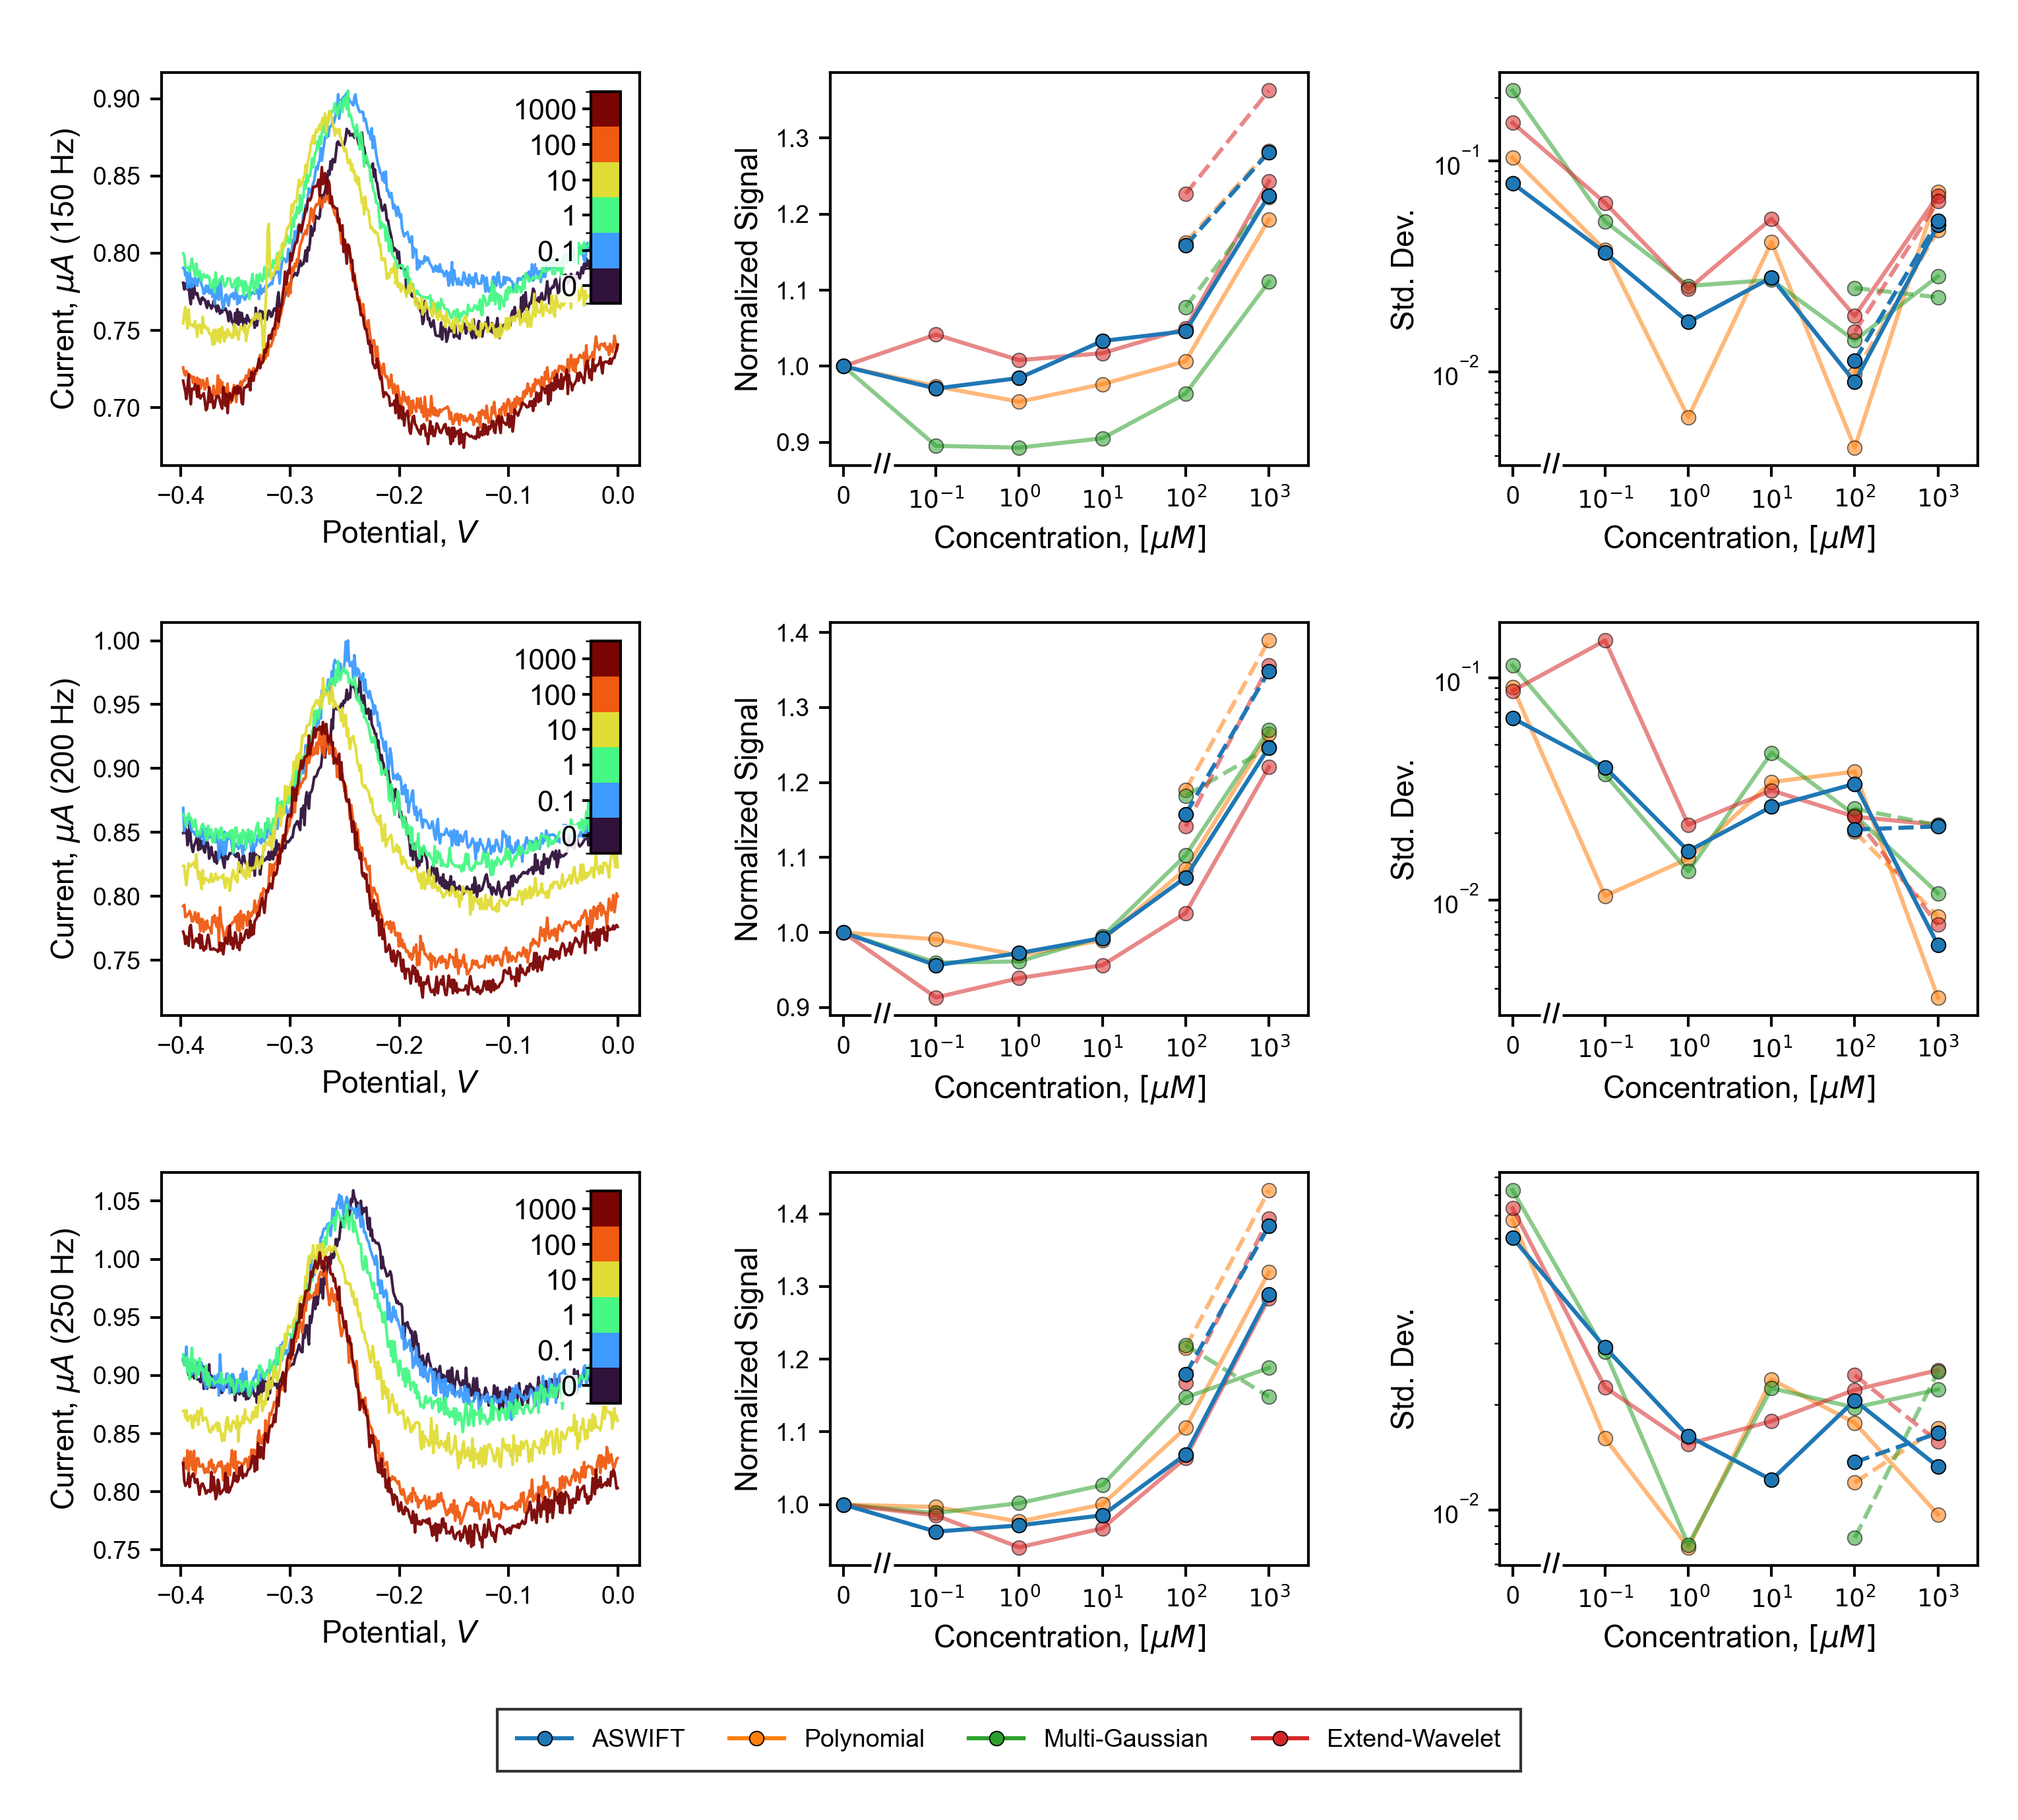

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
if ROOT.name == 'figures': ROOT = ROOT.parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
import json
import pandas as pd
from revisions.common import structured
from revisions.plots import plot_atp
from IPython.display import Image, display
OUT = ROOT / 'revisions/results/atp'
metadata = json.loads((OUT / 'metadata.json').read_text())
INPUT_CSV = Path(next(p for p in metadata['inputs'] if p.endswith('ATP_badNPAu_structured.csv')))
raw = structured(INPUT_CSV)
raw = raw[raw.channel == 0].merge(pd.read_csv(ROOT / 'revisions/atp_concentrations.csv'), on=['hz','num'], validate='one_to_one')
fits = pd.read_csv(OUT / 'traces.csv')
summary = pd.read_csv(OUT / 'summary.csv')
plot_atp(raw, fits, summary, OUT, known=True)
display(Image(filename=str(OUT / 'SI_ATP.png')))
